# Datos Faltantes

In [1]:
# Importar librerías necesarias
import pandas as pd
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.impute import SimpleImputer, KNNImputer
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Cargar el conjunto de datos
diabetes = load_diabetes(as_frame=True)
data = diabetes.data
data['target'] = diabetes.target

In [3]:
data.sample(10)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
295,-0.052738,0.050680,0.039062,-0.040099,-0.005697,-0.012900,0.011824,-0.039493,0.016307,0.003064,85.0
288,0.070769,0.050680,-0.016984,0.021872,0.043837,0.056305,0.037595,-0.002592,-0.070209,-0.017646,80.0
114,0.023546,-0.044642,0.110198,0.063187,0.013567,-0.032942,-0.024993,0.020655,0.099241,0.023775,258.0
296,0.067136,-0.044642,-0.061174,-0.040099,-0.026336,-0.024487,0.033914,-0.039493,-0.056153,-0.059067,89.0
30,-0.060003,-0.044642,0.044451,-0.019442,-0.009825,-0.007577,0.022869,-0.039493,-0.027129,-0.009362,129.0
221,-0.045472,-0.044642,-0.038540,-0.026328,-0.015328,0.000878,-0.032356,-0.002592,0.001148,-0.038357,93.0
370,0.019913,-0.044642,-0.057941,-0.057313,-0.001569,-0.012587,0.074412,-0.039493,-0.061176,-0.075636,63.0
282,0.070769,-0.044642,-0.005128,-0.005670,0.087868,0.102965,0.011824,0.034309,-0.008943,0.027917,230.0
420,0.023546,-0.044642,-0.036385,0.000079,0.001183,0.034698,-0.043401,0.034309,-0.033246,0.061054,146.0
267,0.059871,-0.044642,-0.000817,-0.084856,0.075484,0.079478,0.004460,0.034309,0.023371,0.027917,115.0


In [4]:
# Simular valores faltantes
np.random.seed(42)
data.loc[data.sample(frac=0.1).index, 'bmi'] = np.nan
data.loc[data.sample(frac=0.1).index, 'bp'] = np.nan

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado:

### 1. ¿Cuántos valores faltantes hay en cada columna?**

In [5]:
# Contar los valores faltantes por columna
missing_values = data.isnull().sum()
print('Valores faltantes por columna:')
print(missing_values)

# También mostrar el porcentaje
missing_pct = (data.isnull().sum() / len(data)) * 100
print('\nPorcentaje de valores faltantes por columna:')
print(missing_pct.round(2))

Valores faltantes por columna:
age        0
sex        0
bmi       44
bp        44
s1         0
s2         0
s3         0
s4         0
s5         0
s6         0
target     0
dtype: int64

Porcentaje de valores faltantes por columna:
age       0.00
sex       0.00
bmi       9.95
bp        9.95
s1        0.00
s2        0.00
s3        0.00
s4        0.00
s5        0.00
s6        0.00
target    0.00
dtype: float64


### 2. Utiliza imputación simple (media) para llenar los valores faltantes de la columna 'bmi'.

In [6]:
# Imputación simple (media) para la columna bmi
from sklearn.impute import SimpleImputer

bmi_before = data['bmi'].copy()

imputer = SimpleImputer(strategy='mean')
data['bmi'] = imputer.fit_transform(data[['bmi']])

print('Valores faltantes en bmi ANTES:', bmi_before.isnull().sum())
print('Valores faltantes en bmi DESPUES:', data['bmi'].isnull().sum())
print('Media usada para imputar:', round(imputer.statistics_[0], 6))
print()
print('Primeras filas imputadas (antes NaN):')
print(data.loc[bmi_before.isnull()][['bmi']].head(5))

Valores faltantes en bmi ANTES: 44
Valores faltantes en bmi DESPUES: 0
Media usada para imputar: -0.000205

Primeras filas imputadas (antes NaN):
         bmi
9  -0.000205
30 -0.000205
39 -0.000205
55 -0.000205
70 -0.000205


### 3. Utiliza KNNImputer para imputar valores en las columnas 'bmi' y 'bp'. Compara los resultados con los de la imputación simple.

In [7]:
# Recrear datos con NaN para comparacion limpia
from sklearn.impute import KNNImputer

diabetes2 = load_diabetes(as_frame=True)
data2 = diabetes2.data.copy()
data2['target'] = diabetes2.target
np.random.seed(42)
data2.loc[data2.sample(frac=0.1).index, 'bmi'] = np.nan
data2.loc[data2.sample(frac=0.1).index, 'bp']  = np.nan

# Imputacion Simple (media)
data_simple = data2.copy()
simple_imp = SimpleImputer(strategy='mean')
data_simple[['bmi', 'bp']] = simple_imp.fit_transform(data2[['bmi', 'bp']])

# KNN Imputer (k=5)
data_knn = data2.copy()
knn_imp = KNNImputer(n_neighbors=5)
data_knn[['bmi', 'bp']] = knn_imp.fit_transform(data2[['bmi', 'bp']])

mask_bmi = data2['bmi'].isnull()
mask_bp  = data2['bp'].isnull()

print('=== Comparacion en columna BMI (primeras 8 filas imputadas) ===')
comp_bmi = pd.DataFrame({
    'Simple_media': data_simple.loc[mask_bmi, 'bmi'].values[:8],
    'KNN_k5':       data_knn.loc[mask_bmi, 'bmi'].values[:8]
})
print(comp_bmi.round(6).to_string(index=False))

print()
print('=== Comparacion en columna BP (primeras 8 filas imputadas) ===')
comp_bp = pd.DataFrame({
    'Simple_media': data_simple.loc[mask_bp, 'bp'].values[:8],
    'KNN_k5':       data_knn.loc[mask_bp, 'bp'].values[:8]
})
print(comp_bp.round(6).to_string(index=False))

print()
print('=== Estadisticas descriptivas BMI ===')
print('Simple - std:', round(data_simple['bmi'].std(), 6), ' | KNN - std:', round(data_knn['bmi'].std(), 6))
print('Simple - mean:', round(data_simple['bmi'].mean(), 6), ' | KNN - mean:', round(data_knn['bmi'].mean(), 6))
print()
print('=== Estadisticas descriptivas BP ===')
print('Simple - std:', round(data_simple['bp'].std(), 6), ' | KNN - std:', round(data_knn['bp'].std(), 6))
print('Simple - mean:', round(data_simple['bp'].mean(), 6), ' | KNN - mean:', round(data_knn['bp'].mean(), 6))

=== Comparacion en columna BMI (primeras 8 filas imputadas) ===
 Simple_media    KNN_k5
    -0.000205 -0.016122
    -0.000205 -0.000205
    -0.000205 -0.000205
    -0.000205  0.000045
    -0.000205 -0.013751
    -0.000205 -0.013751
    -0.000205  0.007159
    -0.000205 -0.048672

=== Comparacion en columna BP (primeras 8 filas imputadas) ===
 Simple_media    KNN_k5
     0.000465  0.003970
     0.000465 -0.018292
     0.000465 -0.007736
     0.000465  0.048038
     0.000465  0.000465
     0.000465  0.000465
     0.000465 -0.011406
     0.000465 -0.026100

=== Estadisticas descriptivas BMI ===
Simple - std: 0.044583  | KNN - std: 0.045416
Simple - mean: -0.000205  | KNN - mean: 0.000213

=== Estadisticas descriptivas BP ===
Simple - std: 0.045583  | KNN - std: 0.046323
Simple - mean: 0.000465  | KNN - mean: 0.000296


### 4. Genera un histograma comparando los datos antes y después de la imputación en la columna 'bmi'.

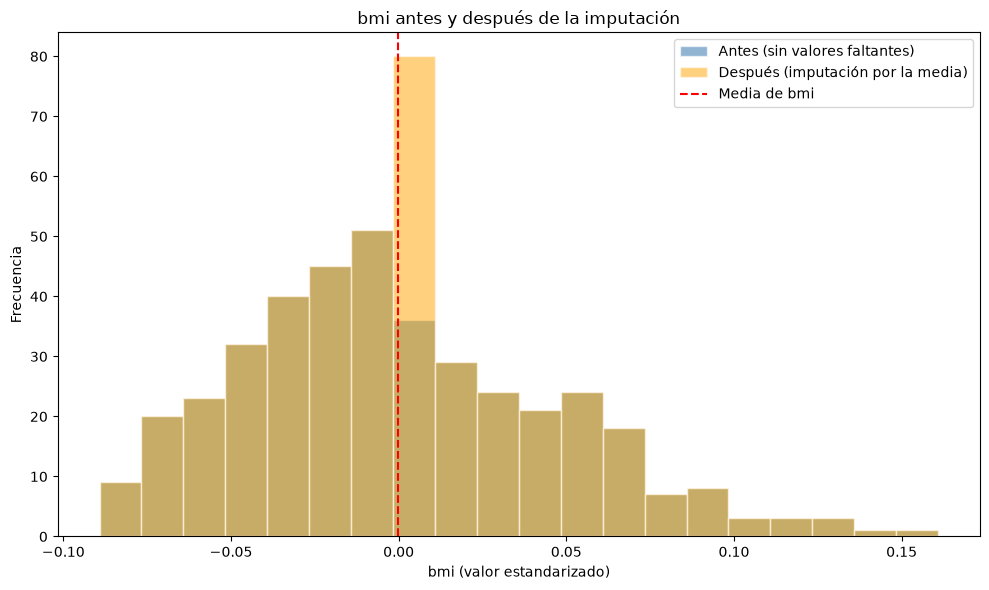

Valores antes: 398; después: 442
Valores imputados: 44
La frecuencia aumenta en el intervalo de la media porque allí se agregan los valores imputados.


In [8]:
# Ejercicio 4: histograma de bmi antes y después de imputar por la media
# bmi_before se guardó en el ejercicio 2 antes de reemplazar los NaN.
antes = bmi_before.dropna()
despues = data['bmi']
bins = np.histogram_bin_edges(pd.concat([antes, despues]), bins=20)

plt.figure(figsize=(10, 6))
plt.hist(antes, bins=bins, alpha=0.6, color='steelblue',
         label='Antes (sin valores faltantes)', edgecolor='white')
plt.hist(despues, bins=bins, alpha=0.5, color='orange',
         label='Después (imputación por la media)', edgecolor='white')
plt.axvline(antes.mean(), color='red', linestyle='--', label='Media de bmi')
plt.title('bmi antes y después de la imputación')
plt.xlabel('bmi (valor estandarizado)')
plt.ylabel('Frecuencia')
plt.legend()
plt.tight_layout()
plt.show()

print(f'Valores antes: {len(antes)}; después: {despues.notna().sum()}')
print(f'Valores imputados: {bmi_before.isna().sum()}')
print('La frecuencia aumenta en el intervalo de la media porque allí se agregan los valores imputados.')
